# Tugas 2 - Progress Final Project (Data Science Basic)
### Bagian 1 dan 2: sumber data dan data preparation

Kasus: menentukan sektor dan wilayah UMKM yang paling layak jadi target awal Klay (aplikasi kasir + analitik, PT Skalar Solusi Digital).
Wilayah yang kami pakai adalah 27 kabupaten/kota di Jawa Barat dengan tahun acuan 2023.

Urutan di notebook ini: sumber data, cleaning, merging, pemetaan sektor, filter penggugur, lalu normalisasi Min-Max. K-Means, skor akhir, dan Top 5 belum dikerjakan karena memang bukan bagian tugas ini.

## Bagian 1. Sumber data

Semua data dari penyedia publik, yaitu Open Data Jabar (Galura) dan BPS Jawa Barat, ditambah satu tabel pembanding dari situs BPS pusat (internet menurut provinsi). Dua tabel (jumlah penduduk dan sinyal 4G) kami ketik ulang dari PDF *Jawa Barat Dalam Angka 2024*, lalu totalnya dicocokkan dengan baris "Jawa Barat" di PDF.

| Dataset | Sumber | Level | Tahun | Dipakai untuk |
|---|---|---|---|---|
| Proyeksi jumlah UMKM (total dan per kategori usaha) | Open Data Jabar | kab/kota | 2016-2023 | ukuran pasar, kepadatan sektor |
| Persentase pemuda pengguna internet, komputer, ponsel | Open Data Jabar (asal BPS) | kab/kota | 2023 | kesiapan digital |
| Desa dengan akses internet, tower BTS, internet di kantor desa | Open Data Jabar | kab/kota | 2020-2024 | kesiapan digital (pelengkap) |
| Desa/kelurahan menurut sinyal internet (Tabel 9.2.2) | BPS Jabar, Dalam Angka 2024 | kab/kota | 2021 | kesiapan digital |
| PDRB per kapita ADHB | BPS Jabar | kab/kota | 2023 | aktivitas ekonomi |
| Jumlah penduduk (Tabel 3.1.3) | BPS Jabar, Dalam Angka 2024 | kab/kota dan provinsi | 2023 | pembagi untuk densitas |
| Industri mikro dan kecil | BPS Jabar | kab/kota | 2023 | pembanding (hanya manufaktur) |
| Pengguna internet menurut provinsi dan umur | BPS | provinsi | 2023 | dicek, tidak dipakai |

Data pembayaran digital (QRIS) per kab/kota tidak kami temukan, jadi komponen itu kosong.

In [31]:
import os, glob, zipfile
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# Folder data_mentah harus ada di samping notebook ini.
# Kalau dijalankan di Colab dan folder belum ada, upload file ZIP-nya di sini.
DATA = "data_mentah"
if not os.path.isdir(DATA):
    zips = glob.glob("*.zip") + glob.glob("/content/*.zip")
    if not zips:
        try:
            from google.colab import files
            print("Upload file ZIP kelompok (isinya folder data_mentah):")
            files.upload()
            zips = glob.glob("*.zip")
        except ImportError:
            pass
    for z in zips:
        zipfile.ZipFile(z).extractall(".")
    if not os.path.isdir(DATA):
        ketemu = glob.glob("**/data_mentah", recursive=True)
        if ketemu:
            DATA = ketemu[0]
assert os.path.isdir(DATA), "Folder data_mentah tidak ketemu. Upload ZIP atau taruh foldernya di samping notebook."

OUT = "output"
os.makedirs(OUT, exist_ok=True)

umkm_total  = pd.read_csv(f"{DATA}/umkm_per_kabkota_2016_2023.csv")
umkm_kat    = pd.read_csv(f"{DATA}/umkm_per_kategori_2017_2023.csv")
pemuda      = pd.read_csv(f"{DATA}/pemuda_teknologi_2023.csv")
desa_akses  = pd.read_csv(f"{DATA}/desa_akses_internet_2021_2024.csv")
desa_bts    = pd.read_csv(f"{DATA}/desa_tower_bts_2020_2024.csv")
desa_kantor = pd.read_csv(f"{DATA}/desa_internet_kantor_desa_2020_2024.csv")
pdrb        = pd.read_csv(f"{DATA}/pdrb_per_kapita_2023.csv", encoding="utf-8-sig")
penduduk    = pd.read_csv(f"{DATA}/penduduk_2023_dalam_angka_tabel_3_1_3.csv")
sinyal      = pd.read_csv(f"{DATA}/sinyal_4g_2021_dalam_angka_tabel_9_2_2.csv")
provinsi    = pd.read_csv(f"{DATA}/provinsi_jabar_2023.csv")
imk_mentah  = pd.read_csv(f"{DATA}/industri_mikro_kecil_2023_bps_mentah.csv", header=None)
inet_mentah = pd.read_csv(f"{DATA}/internet_provinsi_2023_bps_mentah.csv", header=None)

semua = {"umkm_total": umkm_total, "umkm_kat": umkm_kat, "pemuda": pemuda, "desa_akses": desa_akses,
         "desa_bts": desa_bts, "desa_kantor": desa_kantor, "pdrb": pdrb, "penduduk": penduduk,
         "sinyal": sinyal, "provinsi": provinsi, "imk_mentah": imk_mentah, "inet_mentah": inet_mentah}
pd.DataFrame([(k, d.shape[0], d.shape[1]) for k, d in semua.items()], columns=["dataset", "baris", "kolom"])

,dataset,baris,kolom
0,umkm_total,216,8
1,umkm_kat,1890,9
2,pemuda,81,9
3,desa_akses,152,9
4,desa_bts,95,8
5,desa_kantor,95,8
6,pdrb,27,4
7,penduduk,27,5
8,sinyal,27,6
9,provinsi,1,5


## Bagian 2. Data cleaning

### 2.1 Missing value
Hitung dulu sel kosong di tiap dataset.

In [32]:
pd.DataFrame([(k, int(d.isna().sum().sum()), ", ".join(d.columns[d.isna().any()].astype(str))) for k, d in semua.items()],
             columns=["dataset", "sel_kosong", "kolom"])

,dataset,sel_kosong,kolom
0,umkm_total,0,
1,umkm_kat,1,kode_provinsi
2,pemuda,0,
3,desa_akses,0,
4,desa_bts,0,
5,desa_kantor,0,
6,pdrb,0,
7,penduduk,0,
8,sinyal,0,
9,provinsi,0,


Hanya `umkm_kat` yang punya sel kosong di data yang sudah rapi, yaitu satu baris di kolom `kode_provinsi`. Dua tabel BPS yang paling bawah memang masih mentah (ada baris judul), jadi kosongnya wajar dan dirapikan di bawah. Untuk baris yang kosong itu kita lihat dulu nama provinsinya. Satu catatan: tabel internet provinsi 2023 menandai data yang belum ada dengan tanda "-" (bukan sel kosong), sehingga tidak ikut terhitung di tabel di atas. Tanda itu ditangani pada sel pembersihan di bawah.

In [33]:
kosong = umkm_kat[umkm_kat["kode_provinsi"].isna()]
print(kosong[["nama_provinsi", "nama_kabupaten_kota", "kategori_usaha", "tahun"]])

# nama_provinsi di baris itu JAWA BARAT, jadi kodenya 32. Kolom ini juga bukan kunci merge (kuncinya kode kab/kota).
umkm_kat["kode_provinsi"] = umkm_kat["kode_provinsi"].fillna(32).astype(int)
print("Sisa kosong:", int(umkm_kat["kode_provinsi"].isna().sum()))

     nama_provinsi nama_kabupaten_kota kategori_usaha  tahun
1889    JAWA BARAT         KOTA BANJAR   JASA/LAINNYA   2023
Sisa kosong: 0


Sekarang dua tabel BPS yang mentah dirapikan. Tabel industri mikro-kecil punya 3 baris judul dan 1 baris total provinsi. Tabel internet provinsi punya 4 baris judul dan tanda "-" untuk empat provinsi baru di Papua yang belum memiliki data 2023 (nilainya dijadikan kosong, tidak diisi).

In [34]:
# Industri mikro-kecil: buang baris judul, pisahkan total provinsi
imk = imk_mentah.iloc[3:, :2].copy()
imk.columns = ["nama", "imk_unit"]
imk["imk_unit"] = imk["imk_unit"].astype(int)
imk_prov = int(imk.loc[imk["nama"] == "Provinsi Jawa Barat", "imk_unit"].iloc[0])
imk = imk[imk["nama"] != "Provinsi Jawa Barat"].reset_index(drop=True)
print("Kab/kota:", len(imk), "| total provinsi:", imk_prov, "| jumlah 27 wilayah:", int(imk["imk_unit"].sum()))

# Internet per provinsi
umur = ["umur_5_12", "umur_13_15", "umur_16_18", "umur_19_24", "umur_25_plus"]
inet = inet_mentah.iloc[4:].copy()
inet.columns = ["provinsi"] + umur
# Tahun 2023: 4 provinsi baru di Papua bertanda "-" (belum ada data). Diubah jadi NaN, tidak diisi tebakan.
inet[umur] = inet[umur].apply(pd.to_numeric, errors="coerce")
inet["jumlah"] = inet[umur].sum(axis=1, min_count=len(umur))
print("Provinsi tanpa data 2023:", inet.loc[inet["jumlah"].isna(), "provinsi"].tolist())
inet[inet["provinsi"].isin(["JAWA BARAT", "DKI JAKARTA", "INDONESIA"])]

Kab/kota: 27 | total provinsi: 641639 | jumlah 27 wilayah: 641639
Provinsi tanpa data 2023: ['PAPUA BARAT DAYA', 'PAPUA SELATAN', 'PAPUA TENGAH', 'PAPUA PEGUNUNGAN']


,provinsi,umur_5_12,umur_13_15,umur_16_18,umur_19_24,umur_25_plus,jumlah
14,DKI JAKARTA,9.82,4.64,5.25,11.66,68.63,100.0
15,JAWA BARAT,11.93,6.19,7.08,13.86,60.94,100.0
42,INDONESIA,12.27,6.39,7.24,13.74,60.36,100.0


Kolom umur di tabel internet provinsi kalau dijumlah hasilnya sekitar 100 di setiap provinsi yang datanya ada (35 dari 39 baris; empat provinsi baru di Papua belum punya data 2023). Artinya tabel ini menunjukkan komposisi umur pengguna internet (dari 100 pengguna, berapa yang berumur 25+), bukan persentase penduduk yang memakai internet. Selain itu levelnya provinsi saja. Jadi tabel ini tidak kami pakai sebagai indikator kesiapan digital. Kesiapan digital kami ambil dari data pemuda dan sinyal 4G yang tersedia per kab/kota.

### 2.2 Duplikat dan anomali
Beberapa pengecekan dijalankan sekaligus, hasilnya dirangkum dalam satu tabel.

In [35]:
hasil = []
def catat(cek, lolos, hasil_cek, tindakan):
    hasil.append((cek, "OK" if lolos else "catatan", hasil_cek, tindakan))

# duplikat
dup = [int(umkm_total.duplicated(["kode_kabupaten_kota", "tahun"]).sum()),
       int(umkm_kat.duplicated(["kode_kabupaten_kota", "kategori_usaha", "tahun"]).sum()),
       int(desa_akses.duplicated(["kode_kabupaten_kota", "status_keberadaan", "tahun"]).sum()),
       int(pemuda.duplicated(["kode_kabupaten_kota", "penggunaan_teknologi"]).sum())]
catat("Duplikat baris", sum(dup) == 0, f"umkm_total={dup[0]}, umkm_kat={dup[1]}, desa_akses={dup[2]}, pemuda={dup[3]}", "tidak ada yang dihapus")

# jumlah wilayah tiap dataset
n = {"umkm": umkm_total["kode_kabupaten_kota"].nunique(), "pemuda": pemuda["kode_kabupaten_kota"].nunique(),
     "desa": desa_akses["kode_kabupaten_kota"].nunique()}
catat("Cakupan wilayah (target 27)", all(v == 27 for v in n.values()), str(n), "data desa hanya 19 wilayah, tidak diisi")

# jumlah kategori vs total
jml = umkm_kat.groupby(["kode_kabupaten_kota", "tahun"])["proyeksi_jumlah_umkm"].sum().reset_index()
cek = jml.merge(umkm_total, on=["kode_kabupaten_kota", "tahun"], suffixes=("_kat", "_tot"))
sel = int((cek["proyeksi_jumlah_umkm_kat"] - cek["proyeksi_jumlah_umkm_tot"]).abs().max())
catat("Jumlah kategori = total UMKM", sel <= 5, f"selisih terbesar {sel} unit (pembulatan)", "dianggap konsisten")

# pertumbuhan dan porsi sektor antar wilayah
w = umkm_total.pivot(index="kode_kabupaten_kota", columns="tahun", values="proyeksi_jumlah_umkm")
tumbuh = (w[2023] / w[2022] - 1) * 100
catat("Pertumbuhan UMKM 2022-2023 antar wilayah", tumbuh.max() - tumbuh.min() > 0.5,
      f"semua wilayah tumbuh {tumbuh.mean():.2f}% (selisih maks-min {tumbuh.max() - tumbuh.min():.4f} poin)",
      "proyeksi seragam, pertumbuhan tidak dipakai sebagai fitur")

pk = umkm_kat.pivot_table(index=["kode_kabupaten_kota", "tahun"], columns="kategori_usaha", values="proyeksi_jumlah_umkm")
porsi_fnb = pk[["KULINER", "MAKANAN", "MINUMAN"]].sum(axis=1) / pk.sum(axis=1) * 100
catat("Porsi F&B antar wilayah", porsi_fnb.std() > 0.5, f"porsi F&B {porsi_fnb.mean():.2f}% di semua wilayah dan tahun",
      "porsi sektor tidak dipakai sebagai fitur, diganti densitas per 1.000 penduduk")

sama = float((pk["AKSESORIS"] == pk["BATIK"]).mean() * 100)
catat("AKSESORIS vs BATIK", sama < 5, f"angkanya identik di {sama:.0f}% baris", "keduanya bukan sektor sasaran, jadi tidak berpengaruh")

catat("Persentase pemuda di rentang 0-100", bool(pemuda["persentase_pemuda"].between(0, 100).all()),
      f"min {pemuda['persentase_pemuda'].min()}, maks {pemuda['persentase_pemuda'].max()}", "tidak ada yang dibuang")

# desa 2022 vs 2023
b = desa_bts.pivot(index="kode_kabupaten_kota", columns="tahun", values="jumlah_desa")
a = desa_akses.pivot_table(index=["kode_kabupaten_kota", "status_keberadaan"], columns="tahun", values="jumlah_desa")
ib, ia = (b[2022] == b[2023]).mean() * 100, (a[2022] == a[2023]).mean() * 100
catat("Data desa 2022 vs 2023", ib < 50 and ia < 50, f"identik: BTS {ib:.0f}% wilayah, akses internet {ia:.0f}% baris",
      "2023 kemungkinan salinan 2022, hanya dipakai sebagai indikator pelengkap")

# penduduk, IMK, sinyal
catat("Penduduk: L + P = jumlah", bool((penduduk["laki_laki"] + penduduk["perempuan"] == penduduk["jumlah"]).all()),
      f"total 27 wilayah {int(penduduk['jumlah'].sum()):,}", "sama dengan angka Jawa Barat di PDF (49.860.330)")
catat("IMK: jumlah 27 wilayah = total provinsi", int(imk["imk_unit"].sum()) == imk_prov, f"{int(imk['imk_unit'].sum()):,} = {imk_prov:,}", "valid")
tot4g = sinyal[["sinyal_4g", "sinyal_3g", "sinyal_2_5g", "tidak_ada_sinyal"]].sum().tolist()
catat("Sinyal: jumlah 27 wilayah = baris Jawa Barat di PDF", tot4g == [5517, 404, 26, 10], str(tot4g), "valid")

pd.DataFrame(hasil, columns=["pengecekan", "status", "hasil", "tindakan"])

,pengecekan,status,hasil,tindakan
0,Duplikat baris,OK,"umkm_total=0, umkm_kat=0, desa_akses=0, pemuda=0",tidak ada yang dihapus
1,Cakupan wilayah (target 27),catatan,"{'umkm': 27, 'pemuda': 27, 'desa': 19}","data desa hanya 19 wilayah, tidak diisi"
2,Jumlah kategori = total UMKM,OK,selisih terbesar 3 unit (pembulatan),dianggap konsisten
3,Pertumbuhan UMKM 2022-2023 antar wilayah,catatan,semua wilayah tumbuh 6.19% (selisih maks-min 0...,"proyeksi seragam, pertumbuhan tidak dipakai se..."
4,Porsi F&B antar wilayah,catatan,porsi F&B 66.81% di semua wilayah dan tahun,"porsi sektor tidak dipakai sebagai fitur, diga..."
5,AKSESORIS vs BATIK,catatan,angkanya identik di 100% baris,"keduanya bukan sektor sasaran, jadi tidak berp..."
6,Persentase pemuda di rentang 0-100,OK,"min 11.48, maks 99.42",tidak ada yang dibuang
7,Data desa 2022 vs 2023,catatan,"identik: BTS 100% wilayah, akses internet 97% ...","2023 kemungkinan salinan 2022, hanya dipakai s..."
8,Penduduk: L + P = jumlah,OK,"total 27 wilayah 49,860,330",sama dengan angka Jawa Barat di PDF (49.860.330)
9,IMK: jumlah 27 wilayah = total provinsi,OK,"641,639 = 641,639",valid


Untuk outlier, PDRB per kapita dicek dengan aturan IQR (batas atas = Q3 + 1,5 x IQR).

In [36]:
q1, q3 = pdrb["pdrb_per_kapita_adhb_ribu_rupiah"].quantile([0.25, 0.75])
batas = q3 + 1.5 * (q3 - q1)
print(f"Q1 = {q1:,.0f} | Q3 = {q3:,.0f} | batas atas = {batas:,.0f}")
pdrb[pdrb["pdrb_per_kapita_adhb_ribu_rupiah"] > batas][["kabupaten_kota", "pdrb_per_kapita_adhb_ribu_rupiah"]]

Q1 = 29,747 | Q3 = 53,954 | batas atas = 90,264


,kabupaten_kota,pdrb_per_kapita_adhb_ribu_rupiah
14,Karawang,115169
15,Bekasi,121647
20,Kota Bandung,140144


Tiga wilayah di atas memang punya PDRB per kapita tinggi (Karawang dan Bekasi adalah kawasan industri, Kota Bandung pusat ekonomi), dan angkanya bukan salah input. Jadi datanya dipertahankan, tidak dibuang.

### 2.3 Konsistensi nama wilayah
Nama wilayah ditulis berbeda di tiap sumber. Contohnya Bogor:

In [37]:
pd.DataFrame({
    "sumber": ["UMKM, pemuda, desa", "PDRB dan IMK", "Penduduk dan sinyal", "Penduduk dan sinyal"],
    "tulisan di file": ["KABUPATEN BOGOR", "Bogor", "Bogor (di bawah judul Kabupaten)", "Bogor (di bawah judul Kota)"],
    "artinya": ["Kab. Bogor", "Kab. Bogor", "Kab. Bogor", "Kota Bogor"],
})

,sumber,tulisan di file,artinya
0,"UMKM, pemuda, desa",KABUPATEN BOGOR,Kab. Bogor
1,PDRB dan IMK,Bogor,Kab. Bogor
2,Penduduk dan sinyal,Bogor (di bawah judul Kabupaten),Kab. Bogor
3,Penduduk dan sinyal,Bogor (di bawah judul Kota),Kota Bogor


"Bogor" bisa berarti kabupaten atau kota, jadi merge lewat nama polos berisiko tertukar. Caranya: nama diubah jadi kunci (jenis, nama), misalnya ("KAB", "BOGOR") dan ("KOTA", "BOGOR"), lalu dipetakan ke kode wilayah BPS (3201-3279). Semua merge di bawah memakai kode itu.

In [38]:
def buat_kunci(nama, jenis=None):
    t = nama.strip().upper()
    if jenis is not None:                 # sumber yang punya kolom jenis (Kabupaten/Kota)
        return ("KOTA" if jenis.strip().upper() == "KOTA" else "KAB", t)
    if t.startswith("KABUPATEN "): return ("KAB", t[len("KABUPATEN "):])
    if t.startswith("KAB. "):      return ("KAB", t[len("KAB. "):])
    if t.startswith("KOTA "):      return ("KOTA", t[len("KOTA "):])
    return ("KAB", t)                     # tanpa awalan dianggap kabupaten

# daftar induk 27 wilayah dari dataset UMKM
wilayah = umkm_total[umkm_total["tahun"] == 2023][["kode_kabupaten_kota", "nama_kabupaten_kota"]].reset_index(drop=True)
wilayah.columns = ["kode_bps", "nama_asli"]
wilayah["kunci"] = [buat_kunci(x) for x in wilayah["nama_asli"]]
wilayah["nama_standar"] = [("Kab. " if k[0] == "KAB" else "Kota ") + k[1].title() for k in wilayah["kunci"]]
peta = dict(zip(wilayah["kunci"], wilayah["kode_bps"]))

def pasang_kode(df, kunci):
    d = df.copy()
    d["kode_bps"] = [peta.get(k) for k in kunci]
    assert d["kode_bps"].notna().all(), "ada nama yang tidak cocok"
    assert d["kode_bps"].is_unique, "ada kode yang terpakai dua kali"
    d["kode_bps"] = d["kode_bps"].astype(int)
    return d

pdrb2     = pasang_kode(pdrb, [buat_kunci(x) for x in pdrb["kabupaten_kota"]])
imk2      = pasang_kode(imk, [buat_kunci(x) for x in imk["nama"]])
penduduk2 = pasang_kode(penduduk, [buat_kunci(x, j) for x, j in zip(penduduk["nama"], penduduk["jenis"])])
sinyal2   = pasang_kode(sinyal, [buat_kunci(x, j) for x, j in zip(sinyal["nama"], sinyal["jenis"])])
print("Semua nama di PDRB, IMK, penduduk, dan sinyal berhasil dipetakan ke 27 kode, tanpa duplikat.")
wilayah[["kode_bps", "nama_asli", "nama_standar"]].head(6)

Semua nama di PDRB, IMK, penduduk, dan sinyal berhasil dipetakan ke 27 kode, tanpa duplikat.


,kode_bps,nama_asli,nama_standar
0,3201,KABUPATEN BOGOR,Kab. Bogor
1,3202,KABUPATEN SUKABUMI,Kab. Sukabumi
2,3203,KABUPATEN CIANJUR,Kab. Cianjur
3,3204,KABUPATEN BANDUNG,Kab. Bandung
4,3205,KABUPATEN GARUT,Kab. Garut
5,3206,KABUPATEN TASIKMALAYA,Kab. Tasikmalaya


## Bagian 3. Merging

### 3.1 Data level kab/kota
Semua tabel digabung ke daftar 27 wilayah dengan `left join` pada `kode_bps`. Pakai `validate="one_to_one"` supaya langsung error kalau ada baris ganda. Left join dipilih supaya wilayah yang tidak punya data desa tetap ada di tabel (nilainya kosong), tidak hilang.

In [39]:
tabel = wilayah[["kode_bps", "nama_standar"]].copy()
tabel["kode_provinsi"] = 32

def gabung(t, df, kolom):
    return t.merge(df[["kode_bps"] + kolom], on="kode_bps", how="left", validate="one_to_one")

# UMKM total 2023
t23 = umkm_total[umkm_total["tahun"] == 2023].rename(columns={"kode_kabupaten_kota": "kode_bps", "proyeksi_jumlah_umkm": "umkm_total"})
tabel = gabung(tabel, t23, ["umkm_total"])

# UMKM per kategori 2023, satu kolom per kategori
k23 = umkm_kat[umkm_kat["tahun"] == 2023].pivot(index="kode_kabupaten_kota", columns="kategori_usaha", values="proyeksi_jumlah_umkm")
k23.columns = ["umkm_" + c.lower().replace("/", "_") for c in k23.columns]
k23 = k23.reset_index().rename(columns={"kode_kabupaten_kota": "kode_bps"})
tabel = gabung(tabel, k23, list(k23.columns[1:]))

# pemuda pengguna teknologi
pem = pemuda.pivot(index="kode_kabupaten_kota", columns="penggunaan_teknologi", values="persentase_pemuda")
pem = pem.rename(columns={"INTERNET": "pemuda_internet", "KOMPUTER": "pemuda_komputer", "TELEPON SELULER": "pemuda_ponsel"})
pem = pem.reset_index().rename(columns={"kode_kabupaten_kota": "kode_bps"})
tabel = gabung(tabel, pem, ["pemuda_internet", "pemuda_komputer", "pemuda_ponsel"])

# sinyal 4G: persen desa/kelurahan yang dapat sinyal 4G
sinyal2["sinyal_4g_pct"] = sinyal2["sinyal_4g"] / sinyal2[["sinyal_4g", "sinyal_3g", "sinyal_2_5g", "tidak_ada_sinyal"]].sum(axis=1) * 100
tabel = gabung(tabel, sinyal2, ["sinyal_4g_pct"])

# desa 2023 (19 wilayah): persen terhadap total desa
ak = desa_akses[desa_akses["tahun"] == 2023].pivot(index="kode_kabupaten_kota", columns="status_keberadaan", values="jumlah_desa")
ak["total_desa"] = ak["ADA"] + ak["TIDAK ADA"]
ak["desa_akses_internet_pct"] = ak["ADA"] / ak["total_desa"] * 100
ak = ak.reset_index().rename(columns={"kode_kabupaten_kota": "kode_bps"})
bts = desa_bts[desa_bts["tahun"] == 2023].rename(columns={"kode_kabupaten_kota": "kode_bps", "jumlah_desa": "desa_bts"})
kan = desa_kantor[desa_kantor["tahun"] == 2023].rename(columns={"kode_kabupaten_kota": "kode_bps", "jumlah_desa": "desa_kantor_internet"})
tabel = gabung(tabel, ak, ["total_desa", "desa_akses_internet_pct"])
tabel = gabung(tabel, bts, ["desa_bts"])
tabel = gabung(tabel, kan, ["desa_kantor_internet"])
tabel["desa_bts_pct"] = tabel["desa_bts"] / tabel["total_desa"] * 100
tabel["desa_kantor_internet_pct"] = tabel["desa_kantor_internet"] / tabel["total_desa"] * 100
tabel = tabel.drop(columns=["desa_bts", "desa_kantor_internet"])

# PDRB, penduduk, IMK
tabel = gabung(tabel, pdrb2.rename(columns={"pdrb_per_kapita_adhb_ribu_rupiah": "pdrb_per_kapita"}), ["pdrb_per_kapita"])
tabel = gabung(tabel, penduduk2.rename(columns={"jumlah": "penduduk"}), ["penduduk"])
tabel = gabung(tabel, imk2, ["imk_unit"])

print("Ukuran tabel:", tabel.shape)
print("Kolom yang masih kosong:")
print(tabel.isna().sum()[lambda s: s > 0])
print("Wilayah tanpa data desa:", ", ".join(tabel.loc[tabel["total_desa"].isna(), "nama_standar"]))

Ukuran tabel: (27, 25)
Kolom yang masih kosong:
total_desa                  8
desa_akses_internet_pct     8
desa_bts_pct                8
desa_kantor_internet_pct    8
dtype: int64
Wilayah tanpa data desa: Kota Bogor, Kota Sukabumi, Kota Bandung, Kota Cirebon, Kota Bekasi, Kota Depok, Kota Cimahi, Kota Tasikmalaya


Sel kosong hanya ada di kolom desa, dan itu semua kota (kota hanya punya kelurahan, bukan desa). Jadi kosongnya struktural dan sengaja tidak diisi.

### 3.2 Data beda level (kab/kota dengan provinsi)
Ada angka yang hanya tersedia di level provinsi. Tabel provinsi (satu baris, `kode_provinsi = 32`) digabung ke tabel kab/kota lewat `kode_provinsi` dengan `many_to_one`, sehingga tiap kab/kota membawa nilai provinsinya. Dari situ dihitung ukuran relatif:

- `pangsa_umkm_prov_pct`: UMKM kab/kota dibanding total UMKM Jawa Barat (total provinsi = jumlah 27 wilayah, karena dataset tidak punya baris provinsi)
- `pangsa_penduduk_prov_pct`: penduduk kab/kota dibanding penduduk Jawa Barat
- `pdrb_rel_prov`: PDRB per kapita kab/kota dibagi PDRB per kapita Jawa Barat (di atas 1 berarti di atas rata-rata provinsi)

In [40]:
prov = provinsi.rename(columns={"penduduk_2023": "penduduk_prov", "pdrb_per_kapita_adhb_2023_ribu_rp": "pdrb_per_kapita_prov"})
tabel = tabel.merge(prov[["kode_provinsi", "penduduk_prov", "pdrb_per_kapita_prov"]], on="kode_provinsi", how="left", validate="many_to_one")

umkm_prov = int(tabel["umkm_total"].sum())
tabel["pangsa_umkm_prov_pct"] = tabel["umkm_total"] / umkm_prov * 100
tabel["pangsa_penduduk_prov_pct"] = tabel["penduduk"] / tabel["penduduk_prov"] * 100
tabel["pdrb_rel_prov"] = tabel["pdrb_per_kapita"] / tabel["pdrb_per_kapita_prov"]

print("Total UMKM Jawa Barat (jumlah 27 wilayah):", f"{umkm_prov:,}")
print("Jumlah pangsa UMKM:", round(tabel["pangsa_umkm_prov_pct"].sum(), 4), "| jumlah pangsa penduduk:", round(tabel["pangsa_penduduk_prov_pct"].sum(), 4))
print("Jumlah baris setelah merge:", len(tabel))
tabel[["nama_standar", "umkm_total", "pangsa_umkm_prov_pct", "penduduk", "pangsa_penduduk_prov_pct", "pdrb_per_kapita", "pdrb_rel_prov"]].head(6)

Total UMKM Jawa Barat (jumlah 27 wilayah): 7,055,660
Jumlah pangsa UMKM: 100.0 | jumlah pangsa penduduk: 100.0
Jumlah baris setelah merge: 27


,nama_standar,umkm_total,pangsa_umkm_prov_pct,penduduk,pangsa_penduduk_prov_pct,pdrb_per_kapita,pdrb_rel_prov
0,Kab. Bogor,570943,8.091986,5627021,11.285567,51378,0.975822
1,Kab. Sukabumi,409507,5.803950,2802404,5.620508,29374,0.557900
2,Kab. Cianjur,381810,5.411400,2558142,5.130616,22826,0.433534
3,Kab. Bandung,537801,7.622264,3721111,7.463069,41372,0.785778
4,Kab. Garut,394496,5.591199,2683665,5.382365,26914,0.511177
5,Kab. Tasikmalaya,286300,4.057735,1907045,3.824774,24172,0.459099


Tabel internet menurut provinsi dari bagian 2.1 sebenarnya juga level provinsi, tapi tidak kami gabung. Kalau digabung dengan cara di atas, 27 kab/kota akan mendapat angka yang sama persis sehingga tidak membedakan wilayah, dan isinya juga komposisi umur, bukan penetrasi.

## Bagian 4. Pemetaan kategori usaha ke sektor sasaran
Brief ICP menyebut sektor sasaran: ritel, F&B, dan jasa transaksi kecil berulang. Sektor tanpa transaksi harian rutin digugurkan. Data kami memakai kategori usaha Open Data Jabar, jadi kami petakan sendiri ke kelompok di brief (sesuai izin di brief, asal pemetaannya dijelaskan). Pemetaan ini adalah penilaian kami, bukan label dari sumber data.

In [41]:
peta_sektor = pd.DataFrame([
    ("KULINER",      "F&B",           "Ya",    "kafe, warung makan, katering; transaksi hampir tiap hari"),
    ("MAKANAN",      "F&B",           "Ya",    "jual makanan; transaksi hampir tiap hari"),
    ("MINUMAN",      "F&B",           "Ya",    "jual minuman; transaksi hampir tiap hari"),
    ("JASA/LAINNYA", "Jasa (proksi)", "Ya",    "satu-satunya kategori jasa di data, isinya campuran, dipakai sebagai proksi jasa transaksi kecil"),
    ("FASHION",      "Bukan sasaran", "Tidak", "beli pakaian tidak harian"),
    ("KONVEKSI",     "Bukan sasaran", "Tidak", "produksi garmen, umumnya berbasis pesanan"),
    ("CRAFT",        "Bukan sasaran", "Tidak", "kerajinan, produksi dan pesanan"),
    ("AKSESORIS",    "Bukan sasaran", "Tidak", "barang yang dibeli jarang"),
    ("BATIK",        "Bukan sasaran", "Tidak", "produksi berbasis pesanan atau musiman"),
    ("BORDIR",       "Bukan sasaran", "Tidak", "produksi berbasis pesanan"),
], columns=["kategori_data", "kelompok_brief", "lolos", "alasan"])
print("Data tidak punya kategori ritel/perdagangan, jadi ritel tidak bisa diukur (tidak ditebak dari kategori lain).")
peta_sektor

Data tidak punya kategori ritel/perdagangan, jadi ritel tidak bisa diukur (tidak ditebak dari kategori lain).


,kategori_data,kelompok_brief,lolos,alasan
0,KULINER,F&B,Ya,"kafe, warung makan, katering; transaksi hampir..."
1,MAKANAN,F&B,Ya,jual makanan; transaksi hampir tiap hari
2,MINUMAN,F&B,Ya,jual minuman; transaksi hampir tiap hari
3,JASA/LAINNYA,Jasa (proksi),Ya,"satu-satunya kategori jasa di data, isinya cam..."
4,FASHION,Bukan sasaran,Tidak,beli pakaian tidak harian
5,KONVEKSI,Bukan sasaran,Tidak,"produksi garmen, umumnya berbasis pesanan"
6,CRAFT,Bukan sasaran,Tidak,"kerajinan, produksi dan pesanan"
7,AKSESORIS,Bukan sasaran,Tidak,barang yang dibeli jarang
8,BATIK,Bukan sasaran,Tidak,produksi berbasis pesanan atau musiman
9,BORDIR,Bukan sasaran,Tidak,produksi berbasis pesanan


In [42]:
kat_ok = peta_sektor.loc[peta_sektor["lolos"] == "Ya", "kategori_data"].tolist()
kol_sasaran = ["umkm_" + k.lower().replace("/", "_") for k in kat_ok]

tabel["umkm_fnb"] = tabel[["umkm_kuliner", "umkm_makanan", "umkm_minuman"]].sum(axis=1)
tabel["umkm_jasa"] = tabel["umkm_jasa_lainnya"]
tabel["umkm_sasaran"] = tabel[kol_sasaran].sum(axis=1)
tabel["porsi_sasaran_pct"] = tabel["umkm_sasaran"] / tabel["umkm_total"] * 100
tabel["umkm_sasaran_per_1000"] = tabel["umkm_sasaran"] / tabel["penduduk"] * 1000

print("Kategori sasaran:", kat_ok)
tabel[["porsi_sasaran_pct", "umkm_sasaran_per_1000"]].describe().loc[["min", "max", "std"]]

Kategori sasaran: ['KULINER', 'MAKANAN', 'MINUMAN', 'JASA/LAINNYA']


,porsi_sasaran_pct,umkm_sasaran_per_1000
min,78.116280,79.261833
max,78.118787,166.178407
std,0.000474,22.722191


`porsi_sasaran_pct` hampir sama di semua wilayah (simpangan baku sekitar 0,0005), karena data UMKM ini proyeksi dengan komposisi sektor yang sama untuk semua wilayah. Brief mengukur "kepadatan sektor target" sebagai proporsi, tapi proporsi seperti ini tidak bisa membedakan wilayah. Sebagai gantinya kami pakai jumlah UMKM sasaran per 1.000 penduduk (`umkm_sasaran_per_1000`) yang memang bervariasi antar wilayah. Penggantian ini kami catat sebagai keterbatasan.

## Bagian 5. Filter penggugur
Tiga kriteria dari brief dan aturan yang kami pakai:

- A. UMKM sangat kecil: wilayah dengan kurang dari 1% total UMKM Jawa Barat digugurkan. Angka 1% adalah keputusan kami sendiri (parameter `AMBANG_PANGSA`), dan dampaknya diuji di bawah.
- B. Data kunci kosong: wilayah yang salah satu indikator kuncinya kosong digugurkan. Data tidak diisi dengan tebakan.
- C. Sektor tanpa transaksi harian rutin: kategori yang tidak lolos di tabel pemetaan Bagian 4.

In [43]:
AMBANG_PANGSA = 1.0      # persen dari total UMKM Jawa Barat; boleh diubah lalu jalankan ulang dari sel ini
KUNCI = ["umkm_total", "penduduk", "pdrb_per_kapita", "pemuda_internet", "pemuda_komputer", "pemuda_ponsel", "sinyal_4g_pct"]
PELENGKAP = ["desa_akses_internet_pct", "desa_bts_pct", "desa_kantor_internet_pct"]

gugur = []
for _, r in tabel[tabel["pangsa_umkm_prov_pct"] < AMBANG_PANGSA].iterrows():
    gugur.append({"kode_bps": r["kode_bps"], "wilayah": r["nama_standar"], "kriteria": "A. UMKM sangat kecil",
                  "nilai": round(r["pangsa_umkm_prov_pct"], 2), "ambang": f"< {AMBANG_PANGSA}% UMKM Jabar",
                  "alasan": f"{r['umkm_total']:,.0f} UMKM atau {r['pangsa_umkm_prov_pct']:.2f}% dari UMKM Jawa Barat"})

for _, r in tabel[tabel[KUNCI].isna().any(axis=1)].iterrows():
    gugur.append({"kode_bps": r["kode_bps"], "wilayah": r["nama_standar"], "kriteria": "B. Data kunci kosong",
                  "nilai": np.nan, "ambang": "semua indikator kunci terisi",
                  "alasan": "kosong: " + ", ".join(k for k in KUNCI if pd.isna(r[k]))})

tereliminasi = pd.DataFrame(gugur, columns=["kode_bps", "wilayah", "kriteria", "nilai", "ambang", "alasan"])
print("Wilayah dengan data kunci kosong:", int(tabel[KUNCI].isna().any(axis=1).sum()), "dari 27")
print("Wilayah dengan data desa kosong:", int(tabel[PELENGKAP].isna().any(axis=1).sum()), "(tidak digugurkan, alasannya di bawah)")
tereliminasi

Wilayah dengan data kunci kosong: 0 dari 27
Wilayah dengan data desa kosong: 8 (tidak digugurkan, alasannya di bawah)


,kode_bps,wilayah,kriteria,nilai,ambang,alasan
0,3272,Kota Sukabumi,A. UMKM sangat kecil,0.86,< 1.0% UMKM Jabar,"60,865 UMKM atau 0.86% dari UMKM Jawa Barat"
1,3274,Kota Cirebon,A. UMKM sangat kecil,0.87,< 1.0% UMKM Jabar,"61,234 UMKM atau 0.87% dari UMKM Jawa Barat"
2,3279,Kota Banjar,A. UMKM sangat kecil,0.56,< 1.0% UMKM Jabar,"39,422 UMKM atau 0.56% dari UMKM Jawa Barat"


Kenapa data desa tidak dijadikan data kunci: delapan kota kosong di data desa karena memang tidak punya desa, bukan karena datanya hilang. Kalau dijadikan kunci, kedelapan kota itu ikut gugur, padahal kota besar justru kandidat kuat untuk Klay. Kesiapan digital sudah terwakili data pemuda dan sinyal 4G yang lengkap untuk 27 wilayah, jadi data desa hanya sebagai indikator pelengkap.

Uji kepekaan batas 1%: seberapa banyak wilayah yang gugur kalau batasnya diganti.

In [44]:
uji = []
for a in [0.5, 0.75, 1.0, 1.5, 2.0]:
    nama = tabel.loc[tabel["pangsa_umkm_prov_pct"] < a, "nama_standar"].tolist()
    uji.append((f"{a}%", len(nama), ", ".join(nama) if nama else "-"))
pd.DataFrame(uji, columns=["batas", "jumlah_gugur", "wilayah"])

,batas,jumlah_gugur,wilayah
0,0.5%,0,-
1,0.75%,1,Kota Banjar
2,1.0%,3,"Kota Sukabumi, Kota Cirebon, Kota Banjar"
3,1.5%,5,"Kab. Pangandaran, Kota Sukabumi, Kota Cirebon,..."
4,2.0%,8,"Kab. Purwakarta, Kab. Pangandaran, Kota Bogor,..."


Di 1% yang gugur 3 wilayah terkecil (Kota Banjar, Kota Sukabumi, Kota Cirebon). Di 0,75% hanya Kota Banjar, sedangkan di 1,5% mulai ikut Kota Cimahi dan Kab. Pangandaran. Kami ambil 1% karena tiga wilayah itu paling jauh di bawah yang lain, tapi ini keputusan kami dan bisa didiskusikan.

Kriteria C: sektor yang digugurkan.

In [45]:
sektor_gugur = peta_sektor[peta_sektor["lolos"] == "Tidak"][["kategori_data", "alasan"]].copy()
total_jabar = tabel["umkm_total"].sum()
sektor_gugur["umkm_jabar_2023"] = [int(tabel["umkm_" + k.lower()].sum()) for k in sektor_gugur["kategori_data"]]
sektor_gugur["porsi_umkm_jabar_pct"] = (sektor_gugur["umkm_jabar_2023"] / total_jabar * 100).round(2)
sektor_gugur["kriteria"] = "C. Tanpa transaksi harian rutin"
print(f"Sektor tergugur: {sektor_gugur['umkm_jabar_2023'].sum():,} UMKM ({sektor_gugur['porsi_umkm_jabar_pct'].sum():.1f}% dari total)")
print(f"Sektor sasaran yang tersisa: {tabel['umkm_sasaran'].sum():,.0f} UMKM ({tabel['umkm_sasaran'].sum() / total_jabar * 100:.1f}%)")
sektor_gugur[["kategori_data", "kriteria", "umkm_jabar_2023", "porsi_umkm_jabar_pct", "alasan"]]

Sektor tergugur: 1,543,941 UMKM (21.9% dari total)
Sektor sasaran yang tersisa: 5,511,725 UMKM (78.1%)


,kategori_data,kriteria,umkm_jabar_2023,porsi_umkm_jabar_pct,alasan
4,FASHION,C. Tanpa transaksi harian rutin,572525,8.11,beli pakaian tidak harian
5,KONVEKSI,C. Tanpa transaksi harian rutin,349615,4.96,"produksi garmen, umumnya berbasis pesanan"
6,CRAFT,C. Tanpa transaksi harian rutin,586603,8.31,"kerajinan, produksi dan pesanan"
7,AKSESORIS,C. Tanpa transaksi harian rutin,16426,0.23,barang yang dibeli jarang
8,BATIK,C. Tanpa transaksi harian rutin,16426,0.23,produksi berbasis pesanan atau musiman
9,BORDIR,C. Tanpa transaksi harian rutin,2346,0.03,produksi berbasis pesanan


In [46]:
lolos = tabel[~tabel["kode_bps"].isin(tereliminasi["kode_bps"])].reset_index(drop=True)
print(f"Awal {len(tabel)} wilayah, tereliminasi {len(tabel) - len(lolos)}, lolos {len(lolos)}")
print("Tereliminasi:", ", ".join(tereliminasi["wilayah"]))

Awal 27 wilayah, tereliminasi 3, lolos 24
Tereliminasi: Kota Sukabumi, Kota Cirebon, Kota Banjar


## Bagian 6. Normalisasi Min-Max
Rumusnya

$$x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

Semua indikator arahnya positif (makin tinggi makin bagus untuk Klay), jadi tidak ada yang dibalik. Normalisasi dihitung setelah filter, hanya pada wilayah yang lolos, supaya wilayah yang sudah gugur tidak ikut menentukan nilai min dan maks.

Indikator yang dinormalisasi: jumlah UMKM (ukuran pasar), UMKM sasaran per 1.000 penduduk (kepadatan sektor), pemuda internet/komputer/ponsel dan sinyal 4G (kesiapan digital), dan PDRB per kapita (aktivitas ekonomi). Porsi sektor tidak dipakai karena hampir konstan. Komponen pembayaran digital belum ada datanya.

In [47]:
FITUR = {
    "ukuran_pasar": "umkm_total",
    "kepadatan_sektor": "umkm_sasaran_per_1000",
    "digital_internet": "pemuda_internet",
    "digital_komputer": "pemuda_komputer",
    "digital_ponsel": "pemuda_ponsel",
    "digital_4g": "sinyal_4g_pct",
    "aktivitas_ekonomi": "pdrb_per_kapita",
}

# kolom yang nilainya sama semua tidak bisa dinormalisasi (dibagi nol)
cek = pd.DataFrame([(k, c, lolos[c].min(), lolos[c].max(), lolos[c].std()) for k, c in FITUR.items()],
                   columns=["komponen", "kolom", "min", "maks", "simpangan_baku"])
cek["bisa_dinormalisasi"] = cek["maks"] > cek["min"]
cek.round(2)

,komponen,kolom,min,maks,simpangan_baku,bisa_dinormalisasi
0,ukuran_pasar,umkm_total,86635.00,570943.00,139447.97,True
1,kepadatan_sektor,umkm_sasaran_per_1000,79.26,166.18,22.53,True
2,digital_internet,pemuda_internet,92.10,99.02,1.87,True
3,digital_komputer,pemuda_komputer,11.48,51.47,12.13,True
4,digital_ponsel,pemuda_ponsel,94.33,99.42,1.23,True
5,digital_4g,sinyal_4g_pct,78.49,100.00,5.83,True
6,aktivitas_ekonomi,pdrb_per_kapita,22826.00,140144.00,32619.97,True


In [48]:
def min_max(s):
    rentang = s.max() - s.min()
    if rentang == 0:
        raise ValueError(f"{s.name}: semua nilainya sama, tidak bisa dinormalisasi")
    return (s - s.min()) / rentang

norm = lolos[["kode_bps", "nama_standar"]].copy()
for c in FITUR.values():
    norm[c + "_norm"] = min_max(lolos[c])

kolom_norm = [c + "_norm" for c in FITUR.values()]
print("Cek: semua kolom harus punya min 0 dan maks 1")
norm[kolom_norm].agg(["min", "max"]).round(3)

Cek: semua kolom harus punya min 0 dan maks 1


,umkm_total_norm,umkm_sasaran_per_1000_norm,pemuda_internet_norm,pemuda_komputer_norm,pemuda_ponsel_norm,sinyal_4g_pct_norm,pdrb_per_kapita_norm
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [49]:
# contoh sebelum dan sesudah normalisasi (5 wilayah dengan UMKM terbanyak)
contoh = pd.concat([lolos[["nama_standar", "umkm_total", "pdrb_per_kapita", "pemuda_komputer"]],
                    norm[["umkm_total_norm", "pdrb_per_kapita_norm", "pemuda_komputer_norm"]].round(3)], axis=1)
contoh.sort_values("umkm_total", ascending=False).head(5)

,nama_standar,umkm_total,pdrb_per_kapita,pemuda_komputer,umkm_total_norm,pdrb_per_kapita_norm,pemuda_komputer_norm
0,Kab. Bogor,570943,51378,23.14,1.000,0.243,0.292
3,Kab. Bandung,537801,41372,19.52,0.932,0.158,0.201
19,Kota Bandung,523584,140144,43.68,0.902,1.000,0.805
1,Kab. Sukabumi,409507,29374,15.27,0.667,0.056,0.095
4,Kab. Garut,394496,26914,14.97,0.636,0.035,0.087


## Menyimpan hasil

In [50]:
tabel.round(4).to_csv(f"{OUT}/data_bersih_27_wilayah.csv", index=False)
tereliminasi.to_csv(f"{OUT}/wilayah_tereliminasi.csv", index=False)
sektor_gugur[["kategori_data", "kriteria", "umkm_jabar_2023", "porsi_umkm_jabar_pct", "alasan"]].to_csv(f"{OUT}/sektor_tereliminasi.csv", index=False)
norm.round(4).to_csv(f"{OUT}/data_ternormalisasi_wilayah_lolos.csv", index=False)
print(sorted(os.listdir(OUT)))

['data_bersih_27_wilayah.csv', 'data_ternormalisasi_wilayah_lolos.csv', 'sektor_tereliminasi.csv', 'wilayah_tereliminasi.csv']


## Keterbatasan data
1. Data UMKM adalah proyeksi, bukan hasil pencacahan. Pertumbuhannya sama (6,19% per tahun) dan komposisi sektornya sama di semua wilayah, jadi pertumbuhan dan porsi sektor tidak bisa membedakan wilayah. Perbedaan antar wilayah datang dari ukuran dan densitas per penduduk.
2. Ritel tidak terukur karena tidak ada kategori ritel/perdagangan. Jasa hanya diwakili kategori "Jasa/Lainnya" yang isinya campuran.
3. Data pembayaran digital (QRIS) per kab/kota tidak ada, jadi komponen itu kosong.
4. Kesiapan digital memakai persentase pemuda (bukan seluruh penduduk), dan sinyal 4G adalah data 2021 tentang infrastruktur, bukan jumlah pengguna.
5. Data desa hanya 19 wilayah, dan angka tower BTS dan akses internet 2023 kemungkinan salinan 2022. Hanya dipakai sebagai pelengkap.
6. Pemetaan kategori usaha ke sektor sasaran, serta batas 1% pada kriteria A, adalah keputusan kelompok. Batas 1% sudah diuji kepekaannya di Bagian 5.
7. Jumlah penduduk 2023 adalah proyeksi BPS, dan PDRB 2023 masih angka sementara.

##Bagian 7. Exploratory Data Analysis (EDA) & Visualisasi

### 7.1 Persiapan Data Visualisasi

EDA dilakukan untuk mengidentifikasi karakteristik pasar UMKM di 24 kabupaten/kota Jawa Barat yang lolos kriteria penggugur. Analisis difokuskan pada dua sektor sasaran yang dapat diidentifikasi dari dataset, yaitu F&B dan Jasa (proksi).

Indikator yang dianalisis mencakup jumlah UMKM sasaran, kepadatan UMKM sasaran per 1.000 penduduk, PDRB per kapita, serta kesiapan digital wilayah. Analisis dilakukan secara univariat, bivariat, dan multivariat untuk memahami distribusi, hubungan antarindikator, serta perbedaan potensi sektor di setiap wilayah.

Perlu diperhatikan bahwa kategori Jasa/Lainnya merupakan kategori campuran dan digunakan sebagai proksi sektor jasa transaksi kecil berulang. Kategori ritel tidak tersedia secara terpisah dalam dataset.


In [51]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Menggunakan data wilayah yang lolos filter
df_eda = lolos.copy()

# Membentuk skor kesiapan digital dari 4 indikator
kolom_digital = [
    "pemuda_internet",
    "pemuda_komputer",
    "pemuda_ponsel",
    "sinyal_4g_pct"
]

# Normalisasi masing-masing indikator untuk kebutuhan perbandingan
for kolom in kolom_digital:
    rentang = df_eda[kolom].max() - df_eda[kolom].min()
    df_eda[kolom + "_norm"] = (
        (df_eda[kolom] - df_eda[kolom].min()) / rentang
        if rentang != 0 else 0
    )

kolom_digital_norm = [c + "_norm" for c in kolom_digital]

df_eda["kesiapan_digital"] = df_eda[kolom_digital_norm].mean(axis=1)

# Normalisasi indikator lain untuk visualisasi multivariat
for kolom in [
    "umkm_total",
    "umkm_fnb",
    "umkm_jasa",
    "umkm_sasaran",
    "umkm_sasaran_per_1000",
    "pdrb_per_kapita"
]:
    rentang = df_eda[kolom].max() - df_eda[kolom].min()
    df_eda[kolom + "_norm"] = (
        (df_eda[kolom] - df_eda[kolom].min()) / rentang
        if rentang != 0 else 0
    )

# Tema visualisasi
HIJAU_TUA = "#174C3C"
HIJAU = "#3F8068"
SAGE = "#83A994"
ORANYE = "#D49A54"
ABU = "#AAB7AE"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 10
})

print("Jumlah wilayah:", len(df_eda))
print("Total UMKM sasaran:", f"{df_eda['umkm_sasaran'].sum():,.0f}")
print("Total UMKM F&B:", f"{df_eda['umkm_fnb'].sum():,.0f}")
print("Total UMKM Jasa (proksi):", f"{df_eda['umkm_jasa'].sum():,.0f}")


Jumlah wilayah: 24
Total UMKM sasaran: 5,385,549
Total UMKM F&B: 4,606,032
Total UMKM Jasa (proksi): 779,517


### 7.2 Visualisasi 1 — Distribusi Jumlah UMKM Sasaran

Visualisasi histogram digunakan untuk melihat distribusi jumlah UMKM sasaran pada 24 kabupaten/kota di Jawa Barat. Jumlah UMKM sasaran merupakan gabungan kategori F&B dan Jasa (proksi).

Analisis ini bertujuan untuk mengetahui variasi ukuran pasar yang relevan dengan target bisnis Klay, sehingga tidak seluruh kategori UMKM yang tidak sesuai dengan kriteria sektor sasaran ikut diperhitungkan.

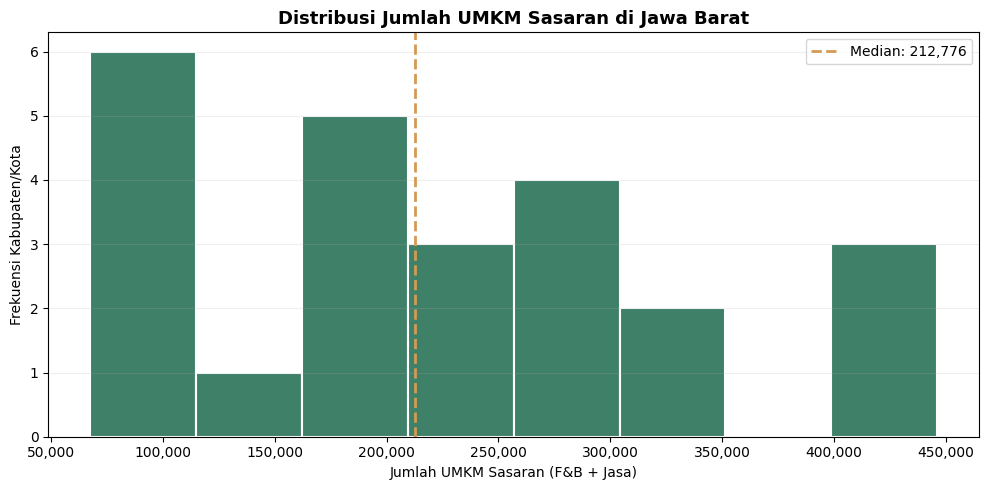

In [52]:

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    df_eda["umkm_sasaran"],
    bins=8,
    color=HIJAU,
    edgecolor="white",
    linewidth=1.5
)

median = df_eda["umkm_sasaran"].median()

ax.axvline(
    median,
    color=ORANYE,
    linestyle="--",
    linewidth=2,
    label=f"Median: {median:,.0f}"
)

ax.set_title("Distribusi Jumlah UMKM Sasaran di Jawa Barat")
ax.set_xlabel("Jumlah UMKM Sasaran (F&B + Jasa)")
ax.set_ylabel("Frekuensi Kabupaten/Kota")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


**Interpretasi Bisnis**

Histogram memperlihatkan persebaran jumlah UMKM yang termasuk dalam sektor sasaran Klay, yaitu F&B dan Jasa (proksi). Perbedaan distribusi menunjukkan bahwa ukuran pasar potensial tidak tersebar secara merata di seluruh kabupaten/kota.

Wilayah dengan jumlah UMKM sasaran lebih besar memiliki basis calon pelanggan potensial yang lebih luas. Namun, jumlah tersebut masih perlu dibandingkan dengan kepadatan UMKM dan kesiapan digital agar prioritas pemasaran tidak hanya didasarkan pada besarnya jumlah usaha.

### 7.3 Visualisasi 2 — Perbandingan Jumlah UMKM F&B dan Jasa per Wilayah

Visualisasi ini membandingkan jumlah UMKM pada sektor F&B dan Jasa (proksi) di setiap kabupaten/kota. Kedua sektor ditampilkan secara berdampingan agar perbedaan ukuran pasar sektoral dapat diamati dengan lebih jelas.

Analisis ini diperlukan untuk mengidentifikasi apakah potensi pasar UMKM di suatu wilayah lebih banyak berasal dari sektor F&B atau Jasa. Sepuluh wilayah dengan jumlah UMKM sasaran terbesar ditampilkan agar perbandingan lebih mudah dibaca.

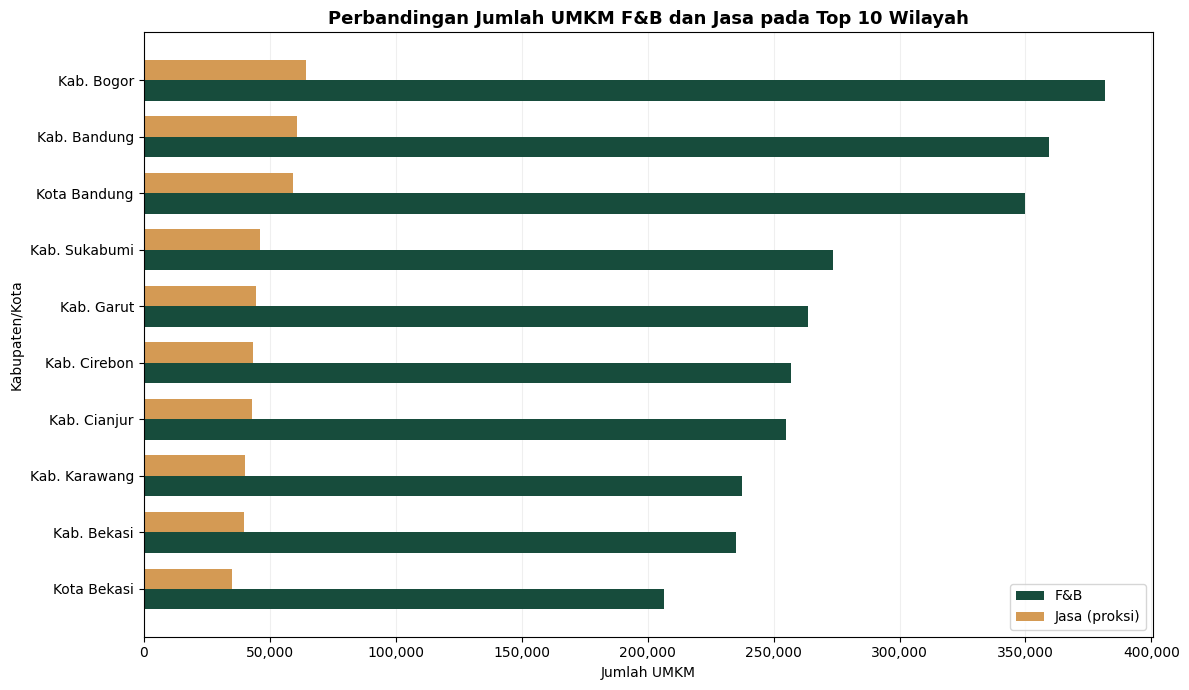

Total F&B: 4,606,032
Total Jasa (proksi): 779,517
Porsi F&B: 85.53%
Porsi Jasa: 14.47%


In [53]:

top_sektor = df_eda.nlargest(
    10, "umkm_sasaran"
).sort_values("umkm_sasaran")

y = np.arange(len(top_sektor))
tinggi = 0.36

fig, ax = plt.subplots(figsize=(12, 7))

bar_fnb = ax.barh(
    y - tinggi/2,
    top_sektor["umkm_fnb"],
    height=tinggi,
    color=HIJAU_TUA,
    label="F&B"
)

bar_jasa = ax.barh(
    y + tinggi/2,
    top_sektor["umkm_jasa"],
    height=tinggi,
    color=ORANYE,
    label="Jasa (proksi)"
)

ax.set_yticks(y)
ax.set_yticklabels(top_sektor["nama_standar"])

ax.set_title("Perbandingan Jumlah UMKM F&B dan Jasa pada Top 10 Wilayah")
ax.set_xlabel("Jumlah UMKM")
ax.set_ylabel("Kabupaten/Kota")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Ringkasan total kedua sektor
print("Total F&B:", f"{df_eda['umkm_fnb'].sum():,.0f}")
print("Total Jasa (proksi):", f"{df_eda['umkm_jasa'].sum():,.0f}")

if df_eda["umkm_fnb"].sum() + df_eda["umkm_jasa"].sum() > 0:
    print(
        "Porsi F&B:",
        f"{df_eda['umkm_fnb'].sum() / df_eda['umkm_sasaran'].sum() * 100:.2f}%"
    )
    print(
        "Porsi Jasa:",
        f"{df_eda['umkm_jasa'].sum() / df_eda['umkm_sasaran'].sum() * 100:.2f}%"
    )


**Interpretasi Bisnis**

Grafik membandingkan kontribusi sektor F&B dan Jasa (proksi) terhadap ukuran pasar UMKM di sepuluh wilayah dengan jumlah UMKM sasaran terbesar.

Perbedaan panjang batang menunjukkan sektor yang memiliki jumlah usaha lebih besar pada masing-masing wilayah. Informasi ini dapat membantu Klay menentukan pendekatan akuisisi pelanggan berdasarkan karakteristik sektor yang lebih dominan.

Namun, hasil untuk sektor Jasa perlu dibaca secara hati-hati karena kategori Jasa/Lainnya mencakup berbagai jenis usaha dan tidak seluruhnya dapat dipastikan memiliki pola transaksi kecil berulang.

### 7.4 Visualisasi 3 — Hubungan PDRB per Kapita dengan Kepadatan UMKM Sasaran

Visualisasi scatter plot digunakan untuk menganalisis hubungan antara PDRB per kapita dan kepadatan UMKM sasaran pada setiap kabupaten/kota.

Sumbu X menunjukkan PDRB per kapita, sedangkan sumbu Y menunjukkan jumlah UMKM sasaran per 1.000 penduduk. Setiap titik diberi label nama wilayah agar identitas kabupaten/kota dapat diketahui secara langsung.

Garis median membagi wilayah menjadi empat kelompok berdasarkan posisi relatif kedua indikator. Nilai korelasi Pearson juga dihitung untuk mengetahui arah dan kekuatan hubungan linear di antara keduanya.

In [54]:
!pip -q install adjustText


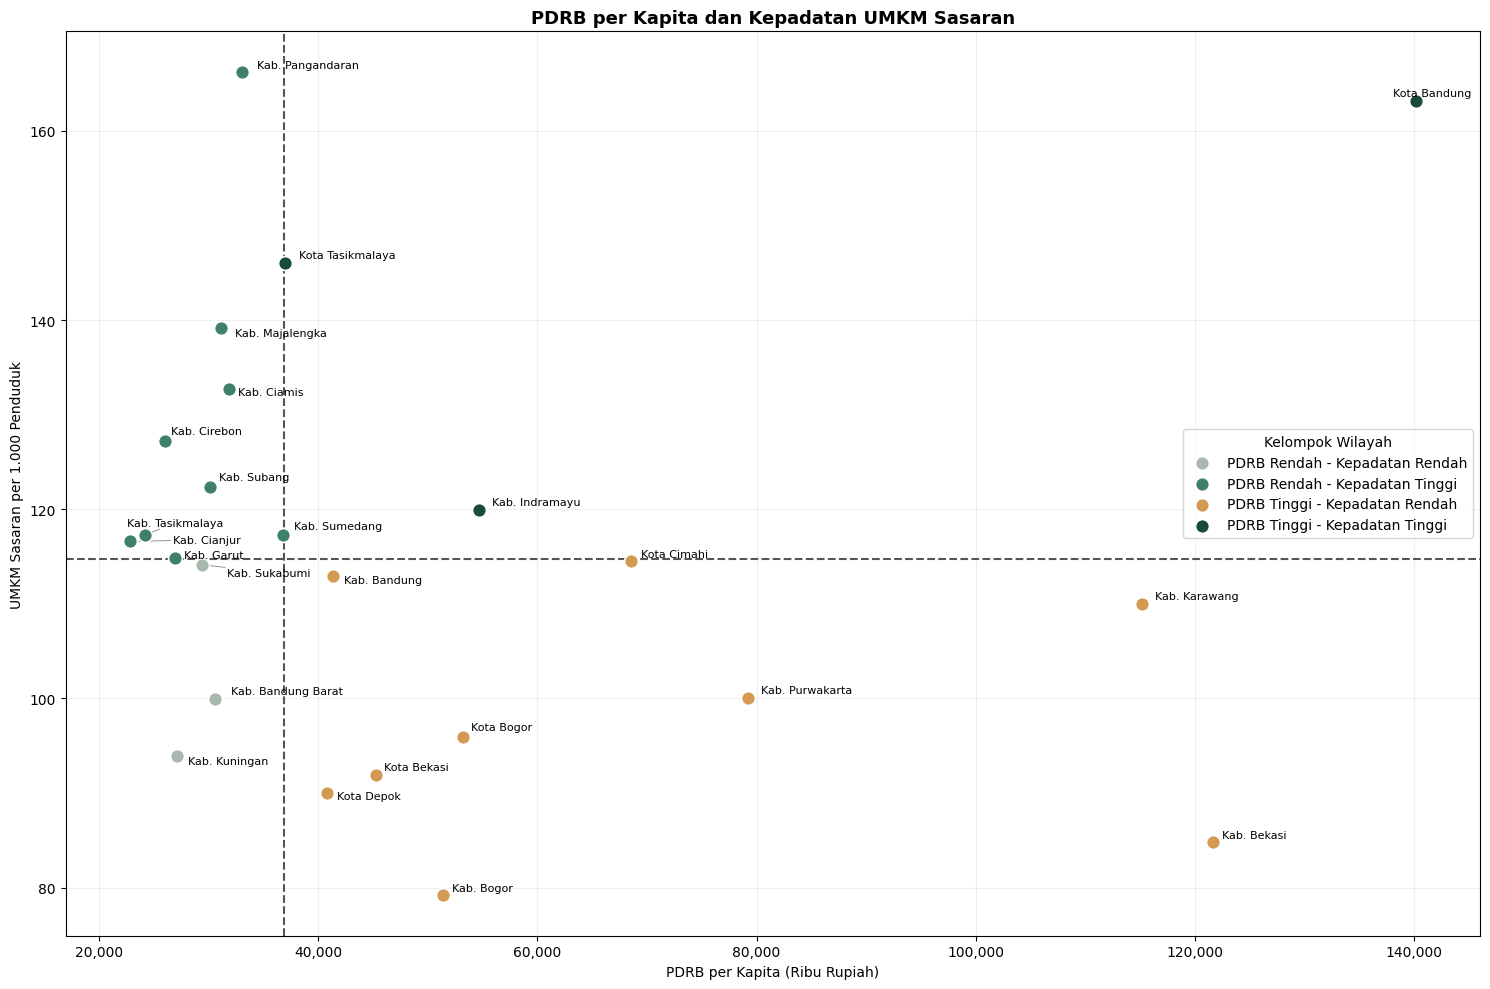

Korelasi Pearson: -0.009

PDRB Rendah - Kepadatan Rendah:
Kab. Sukabumi, Kab. Kuningan, Kab. Bandung Barat

PDRB Rendah - Kepadatan Tinggi:
Kab. Cianjur, Kab. Garut, Kab. Tasikmalaya, Kab. Ciamis, Kab. Cirebon, Kab. Majalengka, Kab. Sumedang, Kab. Subang, Kab. Pangandaran

PDRB Tinggi - Kepadatan Rendah:
Kab. Bogor, Kab. Bandung, Kab. Purwakarta, Kab. Karawang, Kab. Bekasi, Kota Bogor, Kota Bekasi, Kota Depok, Kota Cimahi

PDRB Tinggi - Kepadatan Tinggi:
Kab. Indramayu, Kota Bandung, Kota Tasikmalaya


In [55]:

from adjustText import adjust_text

df_scatter = df_eda[
    ["nama_standar", "pdrb_per_kapita", "umkm_sasaran_per_1000"]
].dropna().copy()

median_pdrb = df_scatter["pdrb_per_kapita"].median()
median_density = df_scatter["umkm_sasaran_per_1000"].median()

def kelompok(row):
    if row["pdrb_per_kapita"] >= median_pdrb and row["umkm_sasaran_per_1000"] >= median_density:
        return "PDRB Tinggi - Kepadatan Tinggi"
    elif row["pdrb_per_kapita"] >= median_pdrb:
        return "PDRB Tinggi - Kepadatan Rendah"
    elif row["umkm_sasaran_per_1000"] >= median_density:
        return "PDRB Rendah - Kepadatan Tinggi"
    return "PDRB Rendah - Kepadatan Rendah"

df_scatter["kelompok"] = df_scatter.apply(kelompok, axis=1)

warna = {
    "PDRB Tinggi - Kepadatan Tinggi": HIJAU_TUA,
    "PDRB Tinggi - Kepadatan Rendah": ORANYE,
    "PDRB Rendah - Kepadatan Tinggi": HIJAU,
    "PDRB Rendah - Kepadatan Rendah": ABU
}

fig, ax = plt.subplots(figsize=(15, 10))

for kategori, data in df_scatter.groupby("kelompok"):
    ax.scatter(
        data["pdrb_per_kapita"],
        data["umkm_sasaran_per_1000"],
        color=warna[kategori],
        s=100,
        label=kategori,
        edgecolor="white",
        linewidth=1.2,
        zorder=3
    )

texts = []
for _, row in df_scatter.iterrows():
    texts.append(
        ax.text(
            row["pdrb_per_kapita"],
            row["umkm_sasaran_per_1000"],
            row["nama_standar"],
            fontsize=8
        )
    )

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.6)
)

ax.axvline(median_pdrb, color="#555555", linestyle="--")
ax.axhline(median_density, color="#555555", linestyle="--")

ax.set_title("PDRB per Kapita dan Kepadatan UMKM Sasaran")
ax.set_xlabel("PDRB per Kapita (Ribu Rupiah)")
ax.set_ylabel("UMKM Sasaran per 1.000 Penduduk")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

ax.legend(title="Kelompok Wilayah")
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

korelasi = df_scatter["pdrb_per_kapita"].corr(
    df_scatter["umkm_sasaran_per_1000"]
)

print(f"Korelasi Pearson: {korelasi:.3f}")

# Menampilkan nama daerah pada masing-masing kuadran
for kategori, data in df_scatter.groupby("kelompok"):
    print(f"\n{kategori}:")
    print(", ".join(data["nama_standar"].tolist()))


**Interpretasi Bisnis**

Berdasarkan hasil evaluasi awal, korelasi Pearson antara PDRB per kapita dan kepadatan UMKM sasaran sebesar **−0,009**, yang menunjukkan hubungan linear sangat lemah atau hampir tidak ada pada data yang dianalisis.

Temuan ini menunjukkan bahwa wilayah dengan aktivitas ekonomi lebih tinggi tidak otomatis memiliki kepadatan UMKM sasaran yang lebih tinggi. Dengan demikian, PDRB per kapita tidak cukup digunakan sebagai satu-satunya dasar untuk menentukan wilayah pemasaran Klay.

Pengelompokan berdasarkan median membantu mengidentifikasi wilayah yang memiliki kombinasi karakteristik berbeda. Wilayah dengan PDRB dan kepadatan UMKM sama-sama tinggi dapat menjadi kandidat awal, sedangkan wilayah dengan kepadatan UMKM tinggi tetapi PDRB lebih rendah tetap perlu dipertimbangkan sebagai pasar potensial.

Nama wilayah pada setiap kelompok ditampilkan melalui hasil kode agar interpretasi akhir menggunakan data aktual, bukan asumsi.

### 7.5 Visualisasi 4 — Perbandingan Kesiapan Digital Wilayah

Visualisasi ini membandingkan kesiapan digital antarwilayah berdasarkan empat indikator, yaitu persentase pemuda pengguna internet, komputer, dan telepon seluler, serta persentase desa/kelurahan yang mendapatkan sinyal 4G.

Setiap indikator dinormalisasi menggunakan Min-Max Scaling sebelum dihitung rata-ratanya. Nilai rata-rata tersebut digunakan sebagai skor komposit untuk membandingkan kesiapan digital relatif antarwilayah.

Sepuluh wilayah dengan nilai tertinggi ditampilkan untuk memudahkan identifikasi wilayah yang memiliki kondisi digital relatif lebih baik.

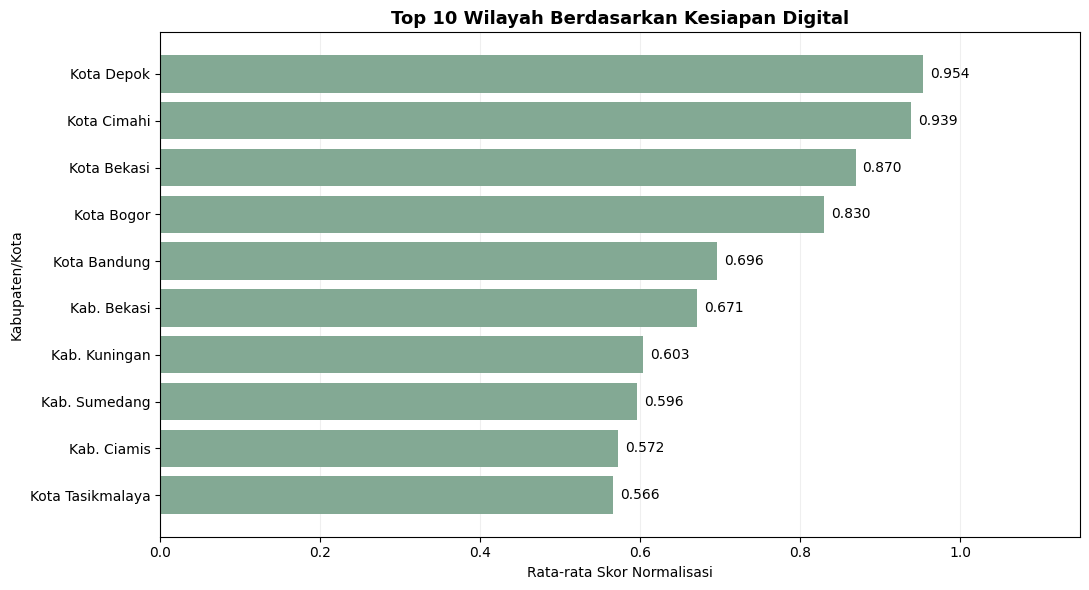

In [26]:

top_digital = df_eda.nlargest(
    10, "kesiapan_digital"
).sort_values("kesiapan_digital")

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    top_digital["nama_standar"],
    top_digital["kesiapan_digital"],
    color=SAGE
)

ax.bar_label(bars, fmt="%.3f", padding=5)

ax.set_title("Top 10 Wilayah Berdasarkan Kesiapan Digital")
ax.set_xlabel("Rata-rata Skor Normalisasi")
ax.set_ylabel("Kabupaten/Kota")
ax.set_xlim(0, 1.15)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Interpretasi Bisnis**

Grafik menunjukkan sepuluh wilayah dengan skor kesiapan digital relatif tertinggi berdasarkan gabungan empat indikator yang digunakan.

Wilayah dengan skor lebih tinggi memiliki kondisi akses dan penggunaan teknologi yang relatif lebih baik dibandingkan wilayah lain dalam dataset. Hal ini dapat menjadi pertimbangan bagi Klay karena penggunaan aplikasi kasir dan analitik membutuhkan dukungan teknologi digital.

Meskipun demikian, skor ini belum menggambarkan adopsi teknologi secara langsung oleh pelaku UMKM. Indikator penggunaan teknologi hanya mencakup kelompok pemuda, sedangkan data 4G menggambarkan kondisi infrastruktur tahun 2021.

### 7.6 Visualisasi 5 — Heatmap Perbandingan Indikator Wilayah dan Sektor

Heatmap digunakan untuk membandingkan karakteristik 24 kabupaten/kota berdasarkan beberapa indikator sekaligus. Indikator yang ditampilkan meliputi jumlah UMKM F&B, jumlah UMKM Jasa (proksi), kepadatan UMKM sasaran, kesiapan digital, dan PDRB per kapita.

Seluruh indikator menggunakan skor normalisasi Min-Max dengan rentang 0 sampai 1. Nilai yang semakin mendekati 1 menunjukkan posisi relatif yang lebih tinggi dibandingkan wilayah lainnya pada indikator tersebut.

Visualisasi ini membantu melihat perbedaan potensi sektor dan kondisi ekonomi maupun digital antarwilayah secara bersamaan.

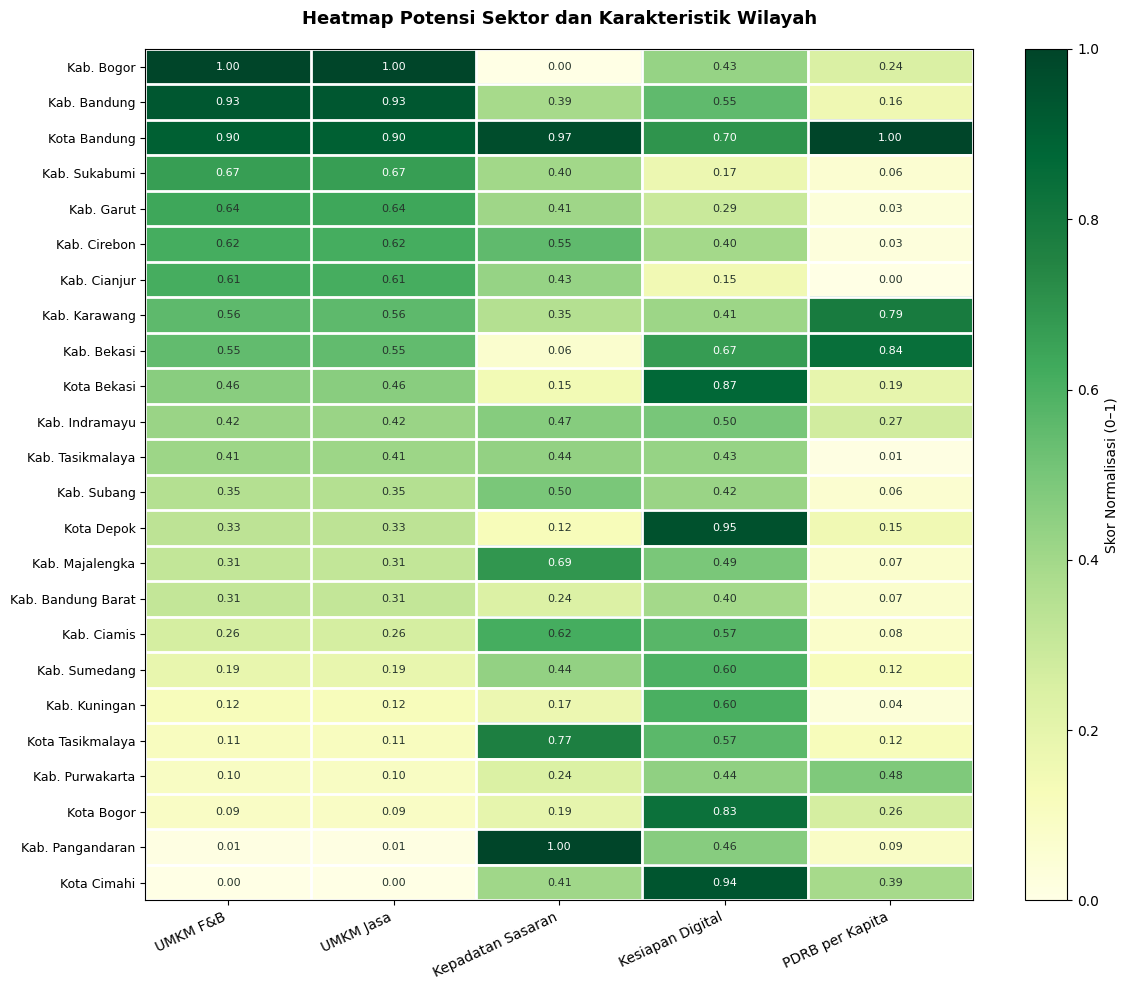

In [27]:

import matplotlib.pyplot as plt
import numpy as np

kolom_heatmap = [
    "umkm_fnb_norm",
    "umkm_jasa_norm",
    "umkm_sasaran_per_1000_norm",
    "kesiapan_digital",
    "pdrb_per_kapita_norm"
]

label_heatmap = [
    "UMKM F&B",
    "UMKM Jasa",
    "Kepadatan Sasaran",
    "Kesiapan Digital",
    "PDRB per Kapita"
]

heatmap_data = (
    df_eda.sort_values("umkm_sasaran", ascending=False)
    .set_index("nama_standar")[kolom_heatmap]
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="YlGn",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

# Label sumbu X dan Y
ax.set_xticks(np.arange(len(label_heatmap)))
ax.set_xticklabels(label_heatmap, rotation=25, ha="right")

ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index, fontsize=9)

# Garis pemisah antar-kotak
ax.set_xticks(np.arange(-0.5, len(label_heatmap), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(heatmap_data.index), 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=2)

# Hilangkan tick kecil
ax.tick_params(which="minor", bottom=False, left=False)

# Tampilkan nilai di dalam setiap kotak
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        nilai = heatmap_data.iloc[i, j]

        warna_teks = "white" if nilai >= 0.65 else "#26352C"

        ax.text(
            j, i,
            f"{nilai:.2f}",
            ha="center",
            va="center",
            color=warna_teks,
            fontsize=8
        )

ax.set_title(
    "Heatmap Potensi Sektor dan Karakteristik Wilayah",
    pad=18
)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Skor Normalisasi (0–1)")

plt.tight_layout()
plt.show()


**Interpretasi Bisnis**

Visualisasi ini membandingkan persebaran UMKM F&B dan Jasa (proksi) terhadap aktivitas ekonomi wilayah yang direpresentasikan oleh PDRB per kapita.

Perbedaan pola kedua sektor dapat memberikan gambaran apakah hubungan antara aktivitas ekonomi dan jumlah UMKM memiliki karakteristik yang berbeda pada masing-masing sektor.

Bagi Klay, analisis ini dapat membantu memahami bahwa potensi pasar tidak hanya ditentukan oleh kondisi ekonomi wilayah, tetapi juga oleh komposisi sektor UMKM yang tersedia. Hasil korelasi untuk masing-masing sektor perlu diperhatikan sebagai informasi pendukung, bukan sebagai hubungan sebab-akibat.

### 7.7 Visualisasi 6 — Pemetaan Potensi Wilayah Berdasarkan Beberapa Indikator

Visualisasi ini menggunakan bubble chart untuk membandingkan beberapa indikator secara bersamaan.

Sumbu X menunjukkan ukuran pasar berdasarkan jumlah UMKM yang telah dinormalisasi, sedangkan sumbu Y menunjukkan kesiapan digital wilayah. Ukuran gelembung menggambarkan kepadatan UMKM sasaran dan warna menunjukkan aktivitas ekonomi berdasarkan PDRB per kapita.

Setiap titik diberi label nama kabupaten/kota agar wilayah yang memiliki karakteristik tertentu dapat diidentifikasi secara langsung.

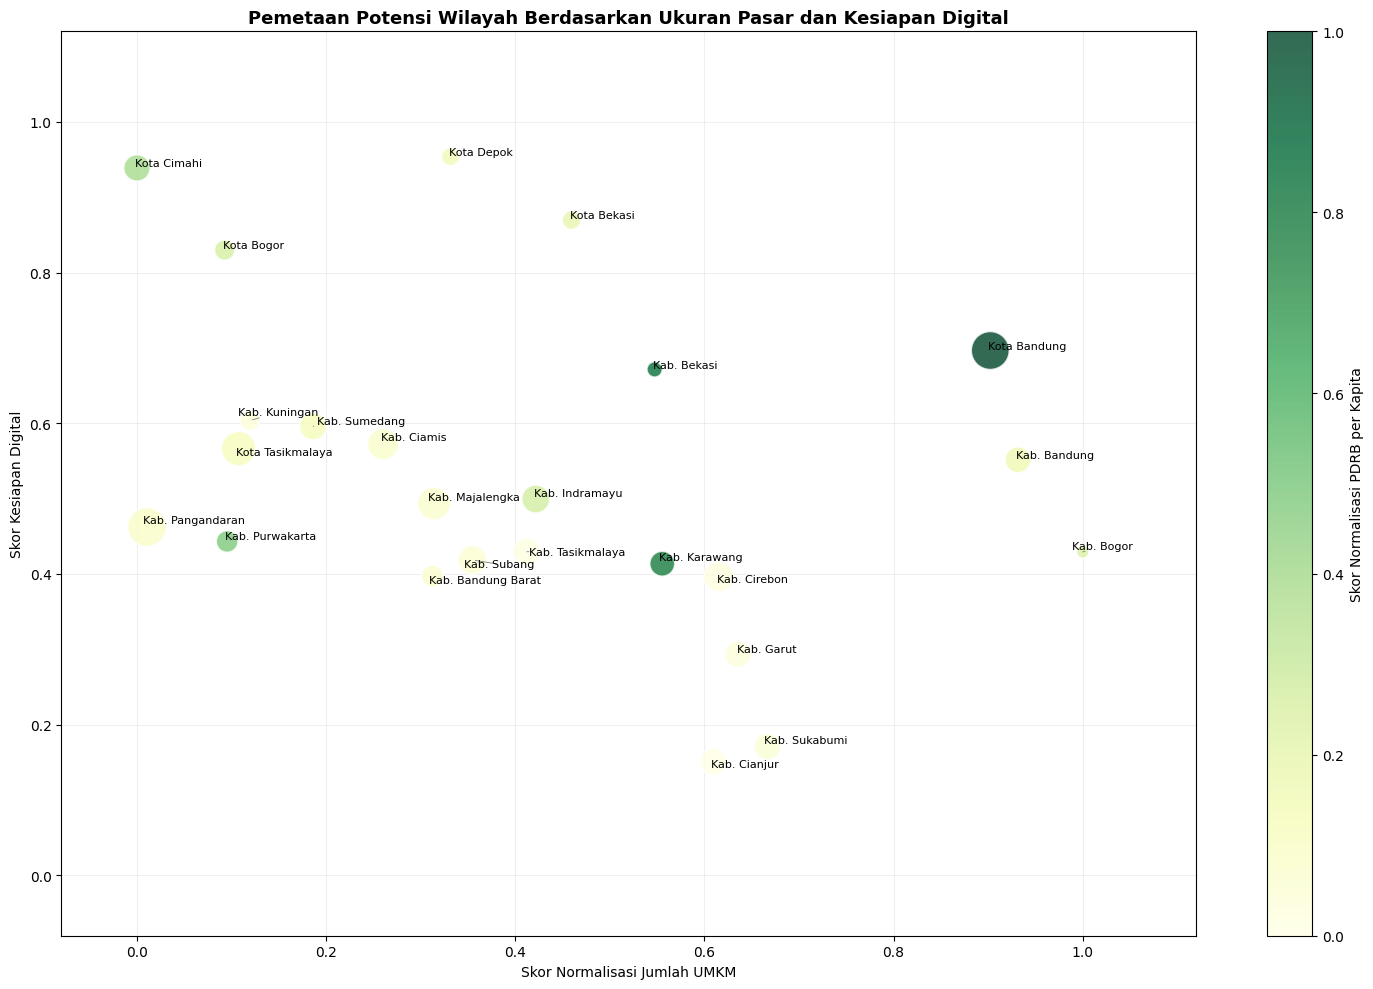

In [28]:

from adjustText import adjust_text

fig, ax = plt.subplots(figsize=(15, 10))

# Ukuran gelembung berdasarkan kepadatan UMKM sasaran
ukuran = (
    80 + df_eda["umkm_sasaran_per_1000_norm"] * 700
)

scatter = ax.scatter(
    df_eda["umkm_total_norm"],
    df_eda["kesiapan_digital"],
    s=ukuran,
    c=df_eda["pdrb_per_kapita_norm"],
    cmap="YlGn",
    vmin=0,
    vmax=1,
    alpha=0.8,
    edgecolor="white",
    linewidth=1.2
)

texts = []
for _, row in df_eda.iterrows():
    texts.append(
        ax.text(
            row["umkm_total_norm"],
            row["kesiapan_digital"],
            row["nama_standar"],
            fontsize=8
        )
    )

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.6)
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Skor Normalisasi PDRB per Kapita")

ax.set_title("Pemetaan Potensi Wilayah Berdasarkan Ukuran Pasar dan Kesiapan Digital")
ax.set_xlabel("Skor Normalisasi Jumlah UMKM")
ax.set_ylabel("Skor Kesiapan Digital")

ax.set_xlim(-0.08, 1.12)
ax.set_ylim(-0.08, 1.12)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Interpretasi Bisnis**

Bubble chart menunjukkan posisi relatif setiap kabupaten/kota berdasarkan ukuran pasar dan kesiapan digital, dengan kepadatan UMKM sasaran serta PDRB per kapita sebagai indikator tambahan.

Wilayah yang berada di bagian kanan atas memiliki ukuran pasar dan kesiapan digital relatif tinggi. Jika wilayah tersebut juga memiliki gelembung lebih besar dan warna yang menunjukkan PDRB relatif tinggi, wilayah tersebut dapat menjadi kandidat awal untuk dipertimbangkan dalam prioritas pemasaran Klay.

Visualisasi ini membantu melihat interaksi beberapa indikator sekaligus, sehingga tidak hanya mengandalkan satu variabel dalam menilai potensi suatu wilayah.

##Bagian 8. Rancangan Formulasi Bobot Indeks Prioritas (ICP)

### 8.1 Dasar Penentuan Bobot ICP

Indeks Customer Prioritization (ICP) dirancang sebagai kerangka awal untuk membantu menentukan wilayah yang berpotensi menjadi target pemasaran Klay, yaitu aplikasi kasir dan analitik penjualan untuk UMKM.

Penentuan komponen bobot mempertimbangkan kesesuaian indikator publik dengan karakteristik bisnis Klay. Empat komponen yang digunakan adalah ukuran pasar, kepadatan sektor sasaran, kesiapan digital, dan aktivitas ekonomi.

Ukuran pasar dihitung menggunakan jumlah UMKM sasaran, yaitu gabungan sektor F&B dan Jasa (proksi), bukan keseluruhan UMKM. Penggunaan indikator ini bertujuan agar pengukuran lebih sesuai dengan sektor yang menjadi target bisnis Klay.

Komponen adopsi pembayaran digital belum dimasukkan karena data QRIS pada tingkat kabupaten/kota tidak tersedia. Nilai komponen tersebut tidak diperkirakan atau diisi menggunakan asumsi.

### 8.2 Rancangan Bobot Awal ICP

Bobot awal disusun berdasarkan pertimbangan strategis kelompok terhadap kontribusi setiap indikator dalam mengidentifikasi potensi pasar Klay. Total bobot seluruh komponen ditetapkan sebesar 100%.

Pada komponen kesiapan digital, empat indikator yang digunakan diberikan bobot internal yang sama karena belum tersedia dasar empiris yang cukup untuk menyatakan bahwa salah satu indikator lebih dominan dibandingkan indikator lainnya.

In [29]:

bobot_icp = pd.DataFrame([
    {
        "Komponen": "Ukuran Pasar",
        "Indikator Publik": "Jumlah UMKM sasaran (F&B + Jasa)",
        "Variabel": "umkm_sasaran",
        "Arah": "Positif (+)",
        "Bobot (%)": 30,
        "Justifikasi Bisnis": "Menggambarkan luasnya basis calon pelanggan yang sesuai dengan target sektor Klay."
    },
    {
        "Komponen": "Kepadatan Sektor Target",
        "Indikator Publik": "UMKM sasaran per 1.000 penduduk",
        "Variabel": "umkm_sasaran_per_1000",
        "Arah": "Positif (+)",
        "Bobot (%)": 25,
        "Justifikasi Bisnis": "Menggambarkan konsentrasi UMKM sasaran dengan mempertimbangkan ukuran populasi wilayah."
    },
    {
        "Komponen": "Kesiapan Digital",
        "Indikator Publik": "Rata-rata persentase pemuda pengguna internet, komputer, ponsel, dan sinyal 4G",
        "Variabel": "Rata-rata 4 indikator digital",
        "Arah": "Positif (+)",
        "Bobot (%)": 25,
        "Justifikasi Bisnis": "Menggambarkan dukungan akses dan penggunaan teknologi digital sebagai lingkungan pendukung penggunaan Klay."
    },
    {
        "Komponen": "Aktivitas Ekonomi",
        "Indikator Publik": "PDRB per kapita ADHB",
        "Variabel": "pdrb_per_kapita",
        "Arah": "Positif (+)",
        "Bobot (%)": 20,
        "Justifikasi Bisnis": "Memberikan gambaran kondisi aktivitas ekonomi wilayah sebagai indikator pendukung potensi pasar."
    }
])

display(bobot_icp)
print("Total bobot:", bobot_icp["Bobot (%)"].sum(), "%")


,Komponen,Indikator Publik,Variabel,Arah,Bobot (%),Justifikasi Bisnis
0,Ukuran Pasar,Jumlah UMKM sasaran (F&B + Jasa),umkm_sasaran,Positif (+),30,Menggambarkan luasnya basis calon pelanggan ya...
1,Kepadatan Sektor Target,UMKM sasaran per 1.000 penduduk,umkm_sasaran_per_1000,Positif (+),25,Menggambarkan konsentrasi UMKM sasaran dengan ...
2,Kesiapan Digital,"Rata-rata persentase pemuda pengguna internet,...",Rata-rata 4 indikator digital,Positif (+),25,Menggambarkan dukungan akses dan penggunaan te...
3,Aktivitas Ekonomi,PDRB per kapita ADHB,pdrb_per_kapita,Positif (+),20,Memberikan gambaran kondisi aktivitas ekonomi ...


Total bobot: 100 %


**Justifikasi Penentuan Bobot**

1. **Ukuran Pasar (30%)**

   Memperoleh bobot terbesar karena jumlah UMKM sasaran menggambarkan luasnya basis calon pelanggan yang relevan dengan target sektor Klay. Penggunaan jumlah UMKM sasaran lebih sesuai dibandingkan jumlah UMKM keseluruhan karena tidak memasukkan kategori usaha yang telah digugurkan.

2. **Kepadatan Sektor Target (25%)**

   Menggambarkan konsentrasi UMKM sasaran terhadap jumlah penduduk. Indikator ini digunakan untuk membedakan wilayah yang memiliki konsentrasi calon pelanggan relatif tinggi, bukan hanya jumlah usaha yang besar karena ukuran populasi.

3. **Kesiapan Digital (25%)**

   Menggunakan empat indikator dengan bobot internal yang sama, yaitu penggunaan internet, komputer, telepon seluler, dan ketersediaan sinyal 4G. Bobot komponen diturunkan menjadi 25% karena data yang tersedia masih berupa proksi kondisi digital wilayah, bukan pengukuran langsung adopsi teknologi oleh pelaku UMKM.

4. **Aktivitas Ekonomi (20%)**

   Menggunakan PDRB per kapita ADHB untuk menggambarkan aktivitas ekonomi wilayah. Indikator ini tetap dipertimbangkan sebagai faktor pendukung, tetapi tidak diberikan bobot dominan karena hasil analisis menunjukkan hubungan yang hampir tidak ada dengan kepadatan UMKM sasaran.

Pembobotan ini merupakan rancangan awal berdasarkan pertimbangan strategis kelompok dan karakteristik data yang tersedia, bukan hasil estimasi statistik.

### 8.3 Visualisasi Komposisi Bobot ICP

Visualisasi ini menunjukkan proporsi bobot yang diberikan pada setiap komponen ICP. Grafik digunakan untuk memperjelas distribusi prioritas indikator dalam rancangan awal indeks.

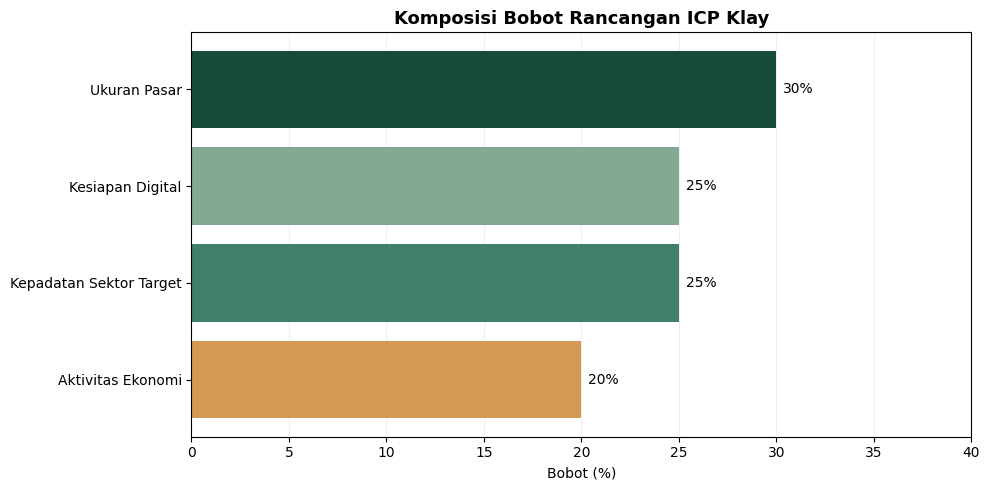

In [30]:

bobot_plot = bobot_icp.sort_values("Bobot (%)")

fig, ax = plt.subplots(figsize=(10, 5))

warna_bobot = [
    ORANYE,
    HIJAU,
    SAGE,
    HIJAU_TUA
]

bars = ax.barh(
    bobot_plot["Komponen"],
    bobot_plot["Bobot (%)"],
    color=warna_bobot
)

ax.bar_label(
    bars,
    labels=[f"{x}%" for x in bobot_plot["Bobot (%)"]],
    padding=5,
    fontsize=10
)

ax.set_title("Komposisi Bobot Rancangan ICP Klay")
ax.set_xlabel("Bobot (%)")
ax.set_xlim(0, 40)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Interpretasi**

Rancangan bobot ICP memberikan prioritas terbesar pada ukuran pasar sebesar 30%, diikuti kepadatan sektor target sebesar 25% dan kesiapan digital sebesar 25%. Aktivitas ekonomi memperoleh bobot sebesar 20%.

Komposisi ini menunjukkan bahwa rancangan indeks lebih menekankan kesesuaian dan konsentrasi calon pelanggan dengan target bisnis Klay, disertai pertimbangan kesiapan digital serta kondisi ekonomi wilayah.

Komponen adopsi pembayaran digital belum dimasukkan karena data QRIS tingkat kabupaten/kota tidak tersedia. Dengan demikian, seluruh bobot dialokasikan pada indikator yang memiliki data pembanding.

### 8.4 Keterbatasan Analisis

Terdapat beberapa keterbatasan yang perlu diperhatikan dalam membaca hasil EDA dan rancangan ICP:

1. **Data UMKM merupakan proyeksi.** Komposisi sektor dan pertumbuhan UMKM relatif seragam antarwilayah, sehingga tidak dapat digunakan untuk membedakan potensi sektor secara langsung.
2. **Kategori ritel tidak tersedia.** Data hanya menyediakan sepuluh kategori usaha dan tidak memiliki kategori ritel tersendiri.
3. **Kategori jasa bersifat campuran.** Kategori Jasa/Lainnya digunakan sebagai proksi untuk sektor jasa, tetapi tidak seluruh usahanya dapat dipastikan memiliki transaksi kecil berulang.
4. **Data QRIS tingkat kabupaten/kota tidak tersedia.** Oleh karena itu, indikator adopsi pembayaran digital belum dimasukkan ke dalam rancangan bobot ICP.
5. **Indikator digital merupakan proksi.** Data pemuda tidak mewakili seluruh pelaku UMKM, sedangkan data sinyal 4G menggambarkan infrastruktur pada tahun 2021, bukan penggunaan aktual.
6. **PDRB per kapita bukan pendapatan UMKM.** Indikator ini digunakan untuk menggambarkan aktivitas ekonomi wilayah secara umum, bukan kemampuan finansial setiap usaha.

Dengan mempertimbangkan keterbatasan tersebut, hasil EDA dan bobot ICP digunakan sebagai dasar awal untuk menyusun prioritas wilayah, bukan sebagai gambaran mutlak mengenai potensi setiap UMKM.